

Instructor Name: Attique-ur-Rehman

Student Name: Zoha Adnan

Sap Id: 70177706

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
df = pd.read_csv(r"C:\Users\LENOVO\Downloads\diabetes.csv")
print(df.shape)
df.head()

(768, 8)


,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,148,72.0,35,169.5,33.6,0.627,50,1
1,85,66.0,29,102.5,26.6,0.351,31,0
2,183,64.0,32,169.5,23.3,0.672,32,1
3,89,66.0,23,94.0,28.1,0.167,21,0
4,137,40.0,35,168.0,43.1,2.288,33,1


In [3]:
print(df.isnull().sum())
print(df['Outcome'].value_counts())

Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64
Outcome
0    500
1    268
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X = df[['Age', 'BMI', 'BloodPressure', 'Insulin', 'Glucose', 'DiabetesPedigreeFunction']]
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [5]:
import os
import pickle

save_path = os.path.join(os.getcwd(), "Mymodel.pkl")
with open(save_path, "wb") as f:
    pickle.dump(model, f)
print("Model saved at:", save_path)

Model saved at: C:\Users\LENOVO\Downloads\Mymodel.pkl


In [6]:
X_test

,Age,BMI,BloodPressure,Insulin,Glucose,DiabetesPedigreeFunction
668,43,34.0,58.0,190.0,98,0.430
324,21,35.7,75.0,102.5,112,0.148
624,21,30.8,64.0,102.5,108,0.158
690,34,24.6,80.0,102.5,107,0.856
473,50,29.9,90.0,102.5,136,0.210
...,...,...,...,...,...,...
355,49,30.4,88.0,169.5,165,0.302
534,24,33.3,56.0,56.0,77,1.251
344,57,36.8,72.0,102.5,95,0.485
296,29,28.0,70.0,360.0,146,0.337


In [7]:
print("Weights:", model.coef_)
print("Intercept:", model.intercept_)

Weights: [[ 0.04559683  0.09394991 -0.00964773  0.00442035  0.03010364  0.48521205]]
Intercept: [-9.2358725]


In [8]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_curve, auc

y_pred = model.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy Score: {accuracy:.4f}")
print(classification_report(y_test, y_pred))
y_pred

Accuracy Score: 0.7597
              precision    recall  f1-score   support

           0       0.82      0.81      0.81        99
           1       0.66      0.67      0.67        55

    accuracy                           0.76       154
   macro avg       0.74      0.74      0.74       154
weighted avg       0.76      0.76      0.76       154



array([0, 0, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 1, 0, 0, 0, 0, 0, 1, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 0, 0, 1, 0, 1, 1, 0,
       0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 1, 0, 0, 1,
       0, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1,
       0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0])

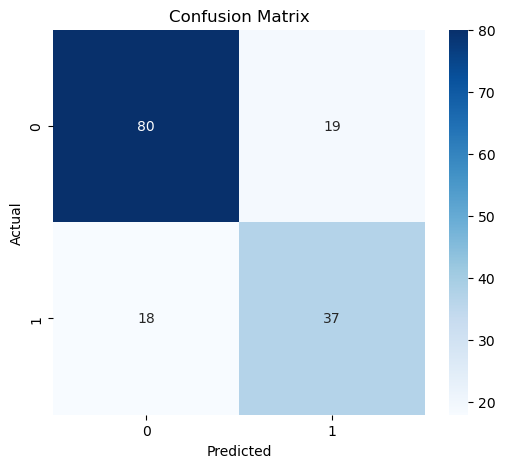

In [9]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

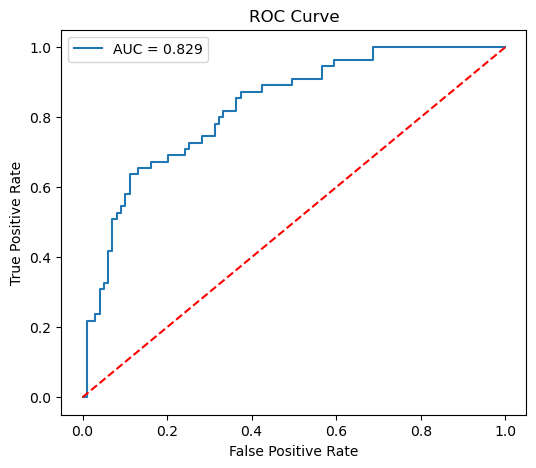

In [10]:
y_prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], 'r--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

In [11]:
new_patient = pd.DataFrame([[21, 35.7, 75.0, 102.5, 112, 0.148]], columns=X.columns)
print("Prediction (1 = diabetic, 0 = not):", model.predict(new_patient)[0])
print("Probability of diabetes:", model.predict_proba(new_patient)[0][1])

Prediction (1 = diabetic, 0 = not): 0
Probability of diabetes: 0.14787040419879446


In [12]:
with open(save_path, "rb") as f:
    loaded_model = pickle.load(f)
print(loaded_model.predict(new_patient)[0])

0
